# Validation with Formation Enthalpy

In [25]:
import csv
import os
import matplotlib.pyplot as plt
from nasa9 import get_H, get_coefficients, get_Cp
import numpy as np

T = 298.15  # K

In [8]:
enthalpies = {}

with open('./table/formation_H.csv', newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    for row in reader:
        if not row or row[0].strip().startswith("#") or row[1] == '':
            continue

        species = row[0].strip()
        enthalpies[species] = float(row[1])

In [9]:
ref_vals, computed_vals, labels, missing = [], [], [], []

for species, H_ref in enthalpies.items():
    try:
        H_calc = get_H(species, T) / 1000.0  # J/mol -> kJ/mol
    except Exception as e:
        missing.append((species, str(e)))
        continue

    ref_vals.append(H_ref)
    computed_vals.append(H_calc)
    labels.append(species)

/var/folders/f5/93qk9czs7835g6z9_k6k6wvc0000gn/T/ipykernel_15533/106134984.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


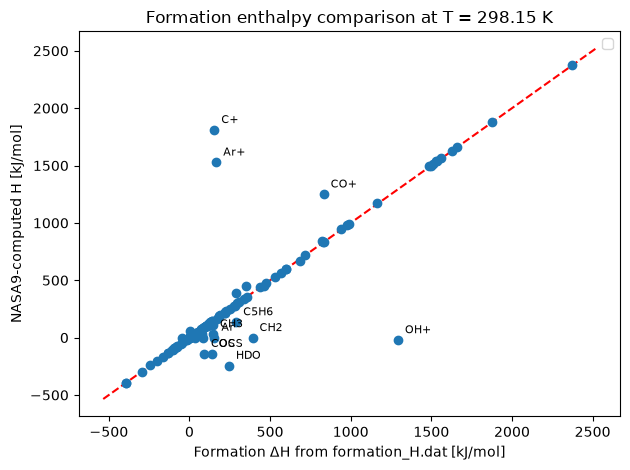

In [ ]:
plt.scatter(ref_vals, computed_vals, zorder=3)

for x, y, label in zip(ref_vals, computed_vals, labels):
    if abs(y-x) > 100:
        plt.annotate(label, (x, y), textcoords="offset points", xytext=(5, 5), fontsize=8)
        print(label)

lo = min(ref_vals + computed_vals)
hi = max(ref_vals + computed_vals)
pad = 0.05 * (hi - lo if hi > lo else 1)
plt.plot([lo - pad, hi + pad], [lo - pad, hi + pad], "r--")

plt.xlabel("Formation ΔH from formation_H.dat [kJ/mol]")
plt.ylabel("NASA9-computed H [kJ/mol]")
plt.title(f"Formation enthalpy comparison at T = {T} K")
plt.legend()
plt.tight_layout()
plt.show()

In [53]:
get_coefficients("Al", T, verbose=True)

AL
Phase: 0 (Gas: 0, Condensed: non-zero)
Molecular weight: 26.9815380
ΔH°(298.15 K) in J/mol: 330000.000
interval 0: 200.0 - 1000.0 K


[5006.60889,
 18.61304407,
 2.412531111,
 0.0001987604647,
 -2.432362152e-07,
 1.538281506e-10,
 -3.944375734e-14,
 38874.1268,
 6.086585765]

In [54]:
get_H("Al", T)

np.float64(329998.1195410799)

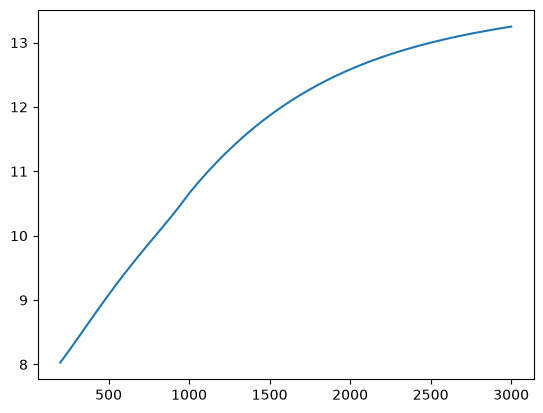

In [43]:
T_list = np.linspace(200, 3000)
tmp = []
for temp in T_list:
    tmp.append(get_Cp("CH2", temp)/4.184)

plt.plot(T_list, tmp)

In [44]:
for i in range(len(tmp)):
    print(f"T: {T_list[i]:.3f}, Cp: {tmp[i]:.3F}")

T: 200.000, Cp: 8.029
T: 257.143, Cp: 8.224
T: 314.286, Cp: 8.426
T: 371.429, Cp: 8.630
T: 428.571, Cp: 8.833
T: 485.714, Cp: 9.032
T: 542.857, Cp: 9.226
T: 600.000, Cp: 9.414
T: 657.143, Cp: 9.595
T: 714.286, Cp: 9.770
T: 771.429, Cp: 9.942
T: 828.571, Cp: 10.113
T: 885.714, Cp: 10.286
T: 942.857, Cp: 10.466
T: 1000.000, Cp: 10.657
T: 1057.143, Cp: 10.828
T: 1114.286, Cp: 10.989
T: 1171.429, Cp: 11.142
T: 1228.571, Cp: 11.286
T: 1285.714, Cp: 11.422
T: 1342.857, Cp: 11.550
T: 1400.000, Cp: 11.672
T: 1457.143, Cp: 11.786
T: 1514.286, Cp: 11.893
T: 1571.429, Cp: 11.994
T: 1628.571, Cp: 12.090
T: 1685.714, Cp: 12.179
T: 1742.857, Cp: 12.263
T: 1800.000, Cp: 12.342
T: 1857.143, Cp: 12.417
T: 1914.286, Cp: 12.487
T: 1971.429, Cp: 12.552
T: 2028.571, Cp: 12.614
T: 2085.714, Cp: 12.671
T: 2142.857, Cp: 12.726
T: 2200.000, Cp: 12.777
T: 2257.143, Cp: 12.825
T: 2314.286, Cp: 12.870
T: 2371.429, Cp: 12.912
T: 2428.571, Cp: 12.952
T: 2485.714, Cp: 12.990
T: 2542.857, Cp: 13.025
T: 2600.000, Cp: 

# Result Comparison

In [66]:
def get_species_list(thermo_path="./table/thermo.inp"):
    with open(thermo_path, encoding="utf-8", errors="ignore") as f:
        lines = f.readlines()

    start = next(i for i, l in enumerate(lines) if l.strip().lower() == "thermo")
    i = start + 2
    n = len(lines)

    species_list = []

    while i < n:
        stripped = lines[i].strip()

        if stripped.startswith(("END", "!")) or not stripped:
            i += 1
            continue

        name = lines[i].split()[0]
        meta = lines[i + 1].split() if i + 1 < n else []

        try:
            n_intervals = int(meta[0])
        except (IndexError, ValueError):
            i += 1
            continue

        species_list.append(name)
        i += 1 + 3 * n_intervals + 1

    return species_list

species_list = get_species_list()

In [ ]:
TEMP = 1000
dH = []
for species in species_list:
    try:
        dH.append(get_H(species, TEMP) - get_H(species, 298.15))
    except:
        continue

dH = np.array(dH) / 1000

Text(0, 0.5, 'frequency')

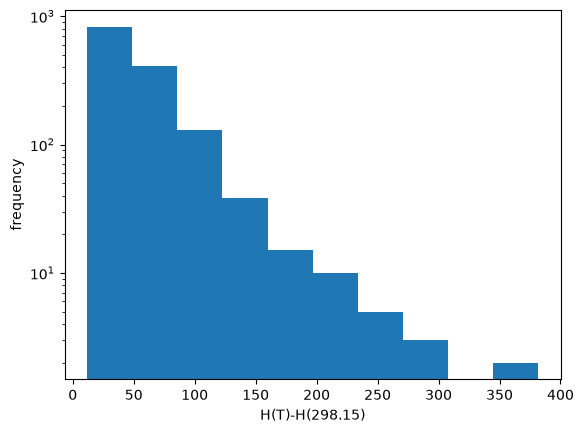

In [74]:
plt.hist(dH)
plt.yscale('log')
plt.xlabel("H(T)-H(298.15)")
plt.ylabel("frequency")